In [22]:
import pandas as pd
import os
import numpy as np
from matplotlib import pyplot as plt
dataraw = "/kinase_ml/data/raw/raw/"

In [3]:
deepkinzero = pd.read_pickle(os.path.join(dataraw,"deepkinzero","deepkinzero_final.pkl"))
phosphoelm = pd.read_pickle(os.path.join(dataraw,"phosphoelm","phosphoelm_final.pkl"))
kinasephos = pd.read_pickle(os.path.join(dataraw,"kinasephos3","kinasephos_final.pkl"))
phosphositeplus = pd.read_pickle(os.path.join(dataraw,"phosphositeplus","phosphositeplus_final.pkl"))

In [4]:
lysateKSI = pd.read_pickle("/kinase_ml/data/interactions/lysate_ksi_cleaned_221115.pkl")

In [5]:
lysateKSI = lysateKSI.loc[:,["kinase","substrate","p_aa","p_ind"]]

In [6]:
lysateKSI["substrate"].drop_duplicates().to_csv("./230703_lysatesubstrateuniprotname.csv",
                                               index = False)

In [7]:
lysateKSI_substrate_id = pd.read_csv("/kinase_ml/code/data_processing/idmapping_2023_07_03.tsv",sep = "\t")

In [8]:
lysateKSI = pd.merge(lysateKSI,lysateKSI_substrate_id,left_on = "substrate",right_on = "From").loc[:,["kinase","Entry","p_aa","p_ind"]]

In [9]:
lysateKSI.columns = ["kinase","substrate","p_aa","p_ind"]

In [10]:
pip install upsetplot

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for upsetplot: filename=upsetplot-0.9.0-py3-none-any.whl size=24863 sha256=5fe6f9bf6536d2fbd41264fe22c14673bc67334c17321f7cfcfde7d61bbd1819
  Stored in directory: /root/.cache/pip/wheels/7b/ce/88/1d0bce5b2680165c29c3e68416325e79674d5a9f422d037996
Successfully built upsetplot
Note: you may need to restart the kernel to use updated packages.


In [11]:
import upsetplot

In [12]:
def add_ks_pair(df,source_name):
    df['ks_pair'] = df.loc[:,'substrate'].astype(str) +"-"+ df.loc[:,'kinase'] +"-"+ df.loc[:,'p_aa'].astype('str') +"-"+ df.loc[:,'p_ind'].astype('str')
    df["source"] = source_name
    return df

In [13]:
lysate_accs = add_ks_pair(lysateKSI,"lysateKSI")

In [14]:
phosphoelm_accs = add_ks_pair(phosphoelm,"phosphoelm_accs")
phosphositeplus_accs = add_ks_pair(phosphositeplus,"phosphositeplus_accs")
kinasephos_accs = add_ks_pair(kinasephos,"kinasephos_accs")

/opt/conda/lib/python3.11/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/opt/conda/lib/python3.11/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/opt/conda/lib/

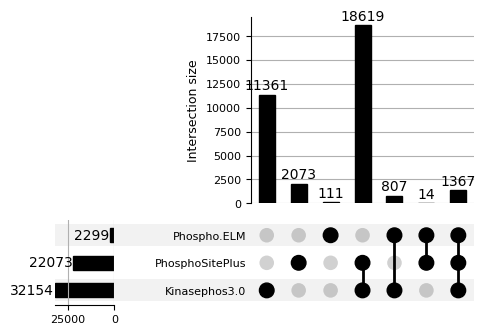

In [26]:
ks_dict = {"Phospho.ELM": list(set(phosphoelm_accs['ks_pair'])),\
          "PhosphoSitePlus":list(set(phosphositeplus_accs['ks_pair'])),\
          "Kinasephos3.0":list(set(kinasephos_accs['ks_pair'])),\
          # "Cell Lysate LC-MS":list(set(lysate_accs['ks_pair']))
          }
upset_data_sub = upsetplot.from_contents(ks_dict)
# Create a taller figure
fig = plt.figure(figsize=(8, 10))  # increase height for longer figure

up = upsetplot.UpSet(
    upset_data_sub,
    show_counts=True,
    element_size=30,   # smaller dots/bars
)

up.plot(fig=fig)

# Reduce font sizes globally for this figure
for ax in fig.axes:
    ax.tick_params(labelsize=8)
    if ax.get_title():
        ax.title.set_fontsize(9)
    ax.xaxis.label.set_size(9)
    ax.yaxis.label.set_size(9)
plt.show()

dataset includes 13 426 experimentally identified phosphorylation sites and their associated 343 kinases
Overall, we curated 24 534 unique kinase–substrate pairs spanning 800 unique kinases from 13 organisms.

In [25]:
ks_dict = {"Phospho.ELM": list(set(phosphoelm_accs['ks_pair'])),\
          "PhosphoSitePlus":list(set(phosphositeplus_accs['ks_pair'])),\
          "Kinasephos3.0":list(set(kinasephos_accs['ks_pair'])),\
          "Cell Lysate LC-MS":list(set(lysate_accs['ks_pair']))
          }
upset_data_sub = upsetplot.from_contents(ks_dict)


# Create a taller figure
fig = plt.figure(figsize=(8, 10))  # increase height for longer figure

up = upsetplot.UpSet(
    upset_data_sub,
    show_counts=True,
    element_size=30,   # smaller dots/bars
)

up.plot(fig=fig)

# Reduce font sizes globally for this figure
for ax in fig.axes:
    ax.tick_params(labelsize=8)
    if ax.get_title():
        ax.title.set_fontsize(9)
    ax.xaxis.label.set_size(9)
    ax.yaxis.label.set_size(9)

# Save as PDF
# plt.show()
plt.savefig("eval_figs/ks_pair_upset.pdf", bbox_inches="tight")
plt.close()



/opt/conda/lib/python3.11/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/opt/conda/lib/python3.11/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/opt/conda/lib/

In [28]:
lysate_ksis = pd.read_pickle("/kinase_ml//data/lysate_ksi_cleaned_221115.pkl")

In [29]:
db_ksis  = pd.read_pickle(os.path.join("/kinase_ml//data/","interactions","interaction_classed_221017.pkl"))

In [30]:
all_kinase_train = db_ksis["kinase"].drop_duplicates().tolist()
n_kinase = len(all_kinase_train)
kinase_organism = pd.read_csv("/kinase_ml/code/data_processing/all_kinase_organism_info.tsv",sep = "\t").loc[:,["From","Organism"]]
kinase_organism.columns = ["kinase","organism"]
interations = pd.read_pickle("/kinase_ml/data/interactions/interaction_classed_221017.pkl")
interations = pd.merge(interations,kinase_organism,on = "kinase")
n_org =  interations["organism"].drop_duplicates().shape[0]
v1_ksi = pd.read_csv('/ksi_ml/data/pairs_aug_v1.csv').iloc[:,1:]
n_ksi_entry = v1_ksi.loc[v1_ksi['label']==1,:].drop_duplicates(['substrate_seq_15aa','kinase_domain_seq','substrate','p_ind']).shape[0]
n_ksi_seq = v1_ksi.loc[v1_ksi['label']==1,:].drop_duplicates(['substrate_seq_15aa','kinase_domain_seq']).shape[0]

print('v1 stats')
print(f'number of kinase in the training data: {n_kinase}')
print(f'number of organism in the training data: {n_org}')
print(f'number of KSI-entry in the training data: {n_ksi_entry}')
print(f'number of KSI-15aasequence in the training data: {n_ksi_seq}')

v1 stats
number of kinase in the training data: 1973
number of organism in the training data: 92
number of KSI-entry in the training data: 29077
number of KSI-15aasequence in the training data: 26267


In [32]:
all_kinase_train = lysate_ksis["kinase"].drop_duplicates().tolist()+db_ksis["kinase"].drop_duplicates().tolist()
n_kinase = len(all_kinase_train)
kinase_organism = pd.read_csv("/kinase_ml/code/data_processing/all_kinase_organism_info.tsv",sep = "\t").loc[:,["From","Organism"]]
kinase_organism.columns = ["kinase","organism"]
n_org = kinase_organism["organism"].drop_duplicates().shape[0]
v2_ksi = pd.read_csv('/ksi_ml/data/pairs_aug_v2.csv').iloc[:,1:]
n_ksi_entry = v2_ksi.loc[v2_ksi['label']==1,:].drop_duplicates(['substrate_seq_15aa','kinase_domain_seq','substrate','p_ind']).shape[0]
n_ksi_seq = v2_ksi.loc[v2_ksi['label']==1,:].drop_duplicates(['substrate_seq_15aa','kinase_domain_seq']).shape[0]
print('v2 stats')
print(f'number of kinase in the training data: {n_kinase}')
print(f'number of organism in the training data: {n_org}')
print(f'number of KSI-entry in the training data: {n_ksi_entry}')
print(f'number of KSI-15aasequence in the training data: {n_ksi_seq}')

v2 stats
number of kinase in the training data: 2304
number of organism in the training data: 92
number of KSI-entry in the training data: 170606
number of KSI-15aasequence in the training data: 147488


In [66]:
import pandas as pd
from plotnine import *

/tmp/ipykernel_3889/937136746.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


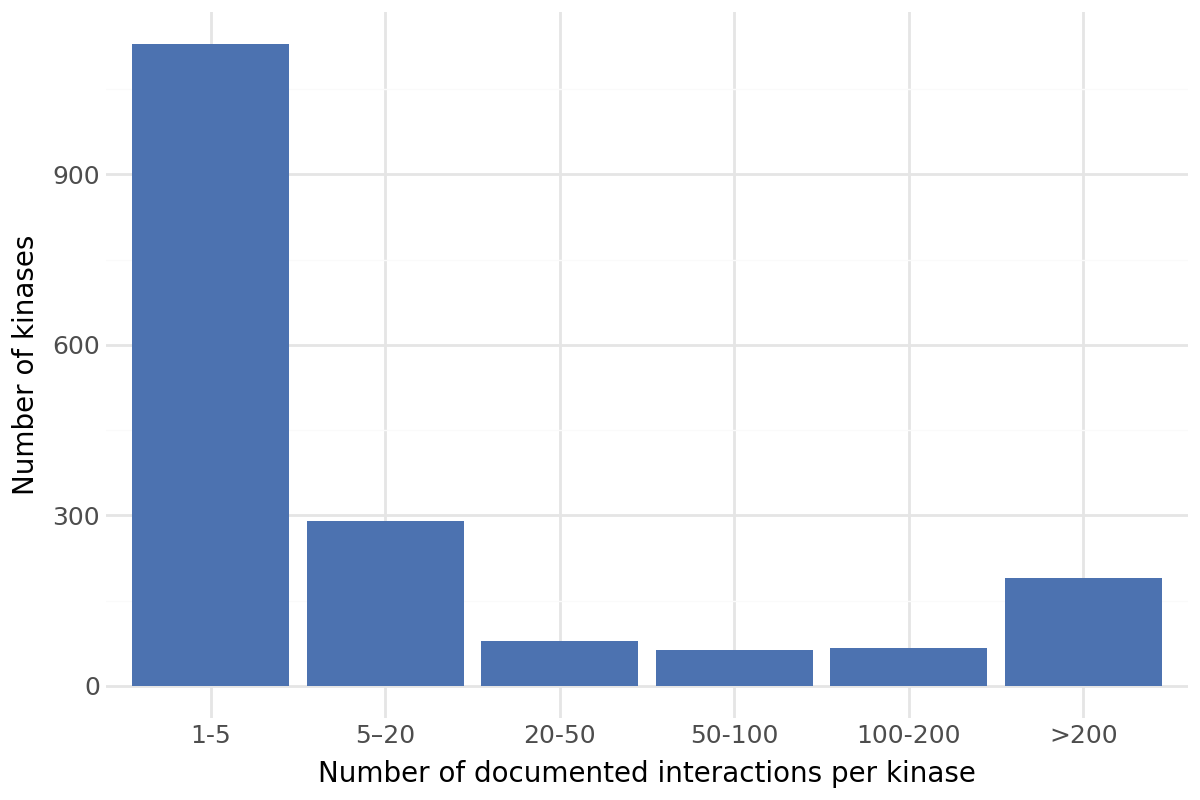

In [74]:
ks_df = v2_ksi.loc[v2_ksi['label']==1,:].drop_duplicates(['substrate_seq_15aa','kinase_domain_seq'])

kinase_counts = (
    ks_df
    .groupby("kinase")
    .size()
    .reset_index(name="n_interactions")
)

bins = [0, 5, 20, 50, 100, 200, float("inf")]
labels = [
    "1-5",
    "5–20",
    "20-50",
    "50-100",
    "100-200",
    ">200"
]

kinase_counts["interaction_bin"] = pd.cut(
    kinase_counts["n_interactions"],
    bins=bins,
    labels=labels,
    right=True,
    include_lowest=True
)

bin_counts = (
    kinase_counts
    .groupby("interaction_bin")
    .size()
    .reset_index(name="n_kinases")
)

# ensure bin order is preserved
bin_counts["interaction_bin"] = pd.Categorical(
    bin_counts["interaction_bin"],
    categories=labels,
    ordered=True
)

a = bin_counts.copy()
a["source"] = "DB + Lysate"

from plotnine import *

p = (
    ggplot(bin_counts, aes(x="interaction_bin", y="n_kinases"))
    + geom_bar(stat="identity", fill="#4C72B0")
    + theme_minimal()
    + theme(
        axis_text_x=element_text(rotation=0, size=9),
        axis_text_y=element_text(size=9),
        axis_title=element_text(size=10),
        figure_size=(6, 4)
    )
    + labs(
        x="Number of documented interactions per kinase",
        y="Number of kinases"
    )
)

p

/tmp/ipykernel_3889/660105492.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


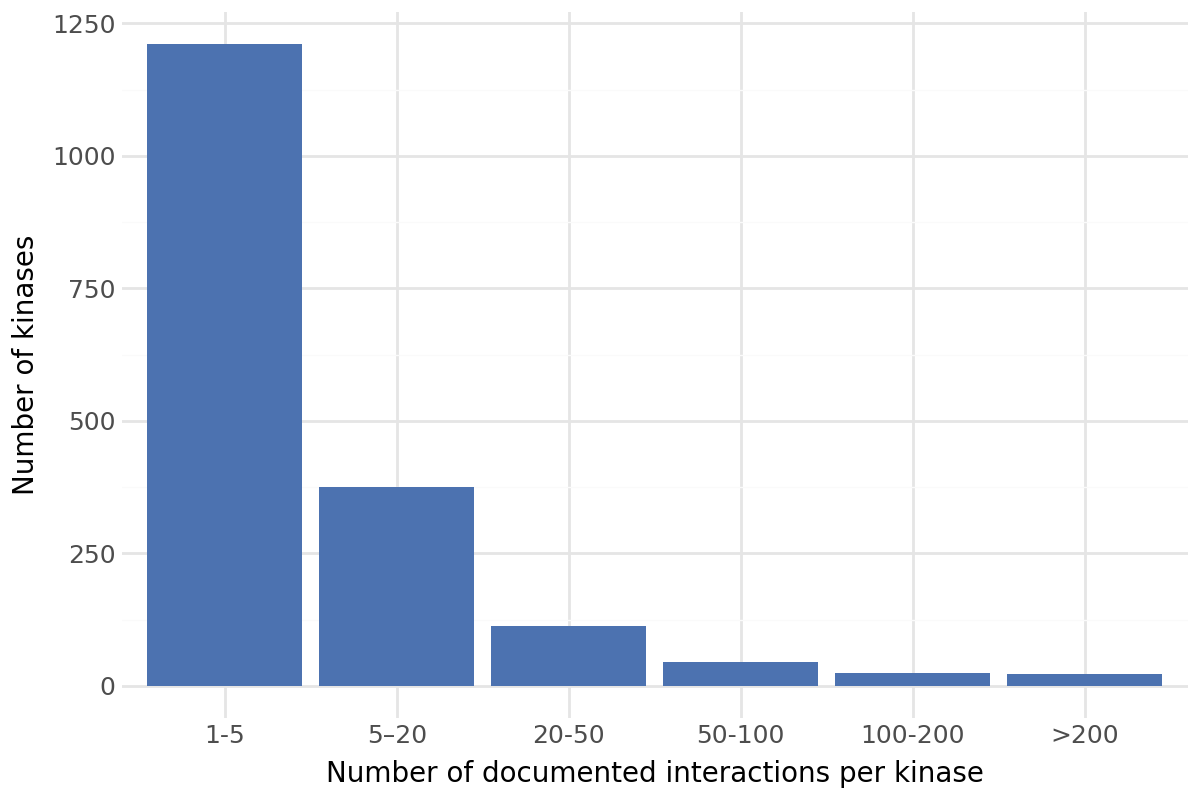

In [75]:
ks_df = v1_ksi.loc[v1_ksi['label']==1,:].drop_duplicates(['substrate_seq_15aa','kinase_domain_seq'])

kinase_counts = (
    ks_df
    .groupby("kinase")
    .size()
    .reset_index(name="n_interactions")
)

bins = [0, 5, 20, 50, 100, 200, float("inf")]
labels = [
    "1-5",
    "5–20",
    "20-50",
    "50-100",
    "100-200",
    ">200"
]

kinase_counts["interaction_bin"] = pd.cut(
    kinase_counts["n_interactions"],
    bins=bins,
    labels=labels,
    right=True,
    include_lowest=True
)

bin_counts = (
    kinase_counts
    .groupby("interaction_bin")
    .size()
    .reset_index(name="n_kinases")
)

# ensure bin order is preserved
bin_counts["interaction_bin"] = pd.Categorical(
    bin_counts["interaction_bin"],
    categories=labels,
    ordered=True
)
b = bin_counts.copy()
b["source"] = "DB Only"
from plotnine import *

p = (
    ggplot(bin_counts, aes(x="interaction_bin", y="n_kinases"))
    + geom_bar(stat="identity", fill="#4C72B0")
    + theme_minimal()
    + theme(
        axis_text_x=element_text(rotation=0, size=9),
        axis_text_y=element_text(size=9),
        axis_title=element_text(size=10),
        figure_size=(6, 4)
    )
    + labs(
        x="Number of documented interactions per kinase",
        y="Number of kinases"
    )
)

p

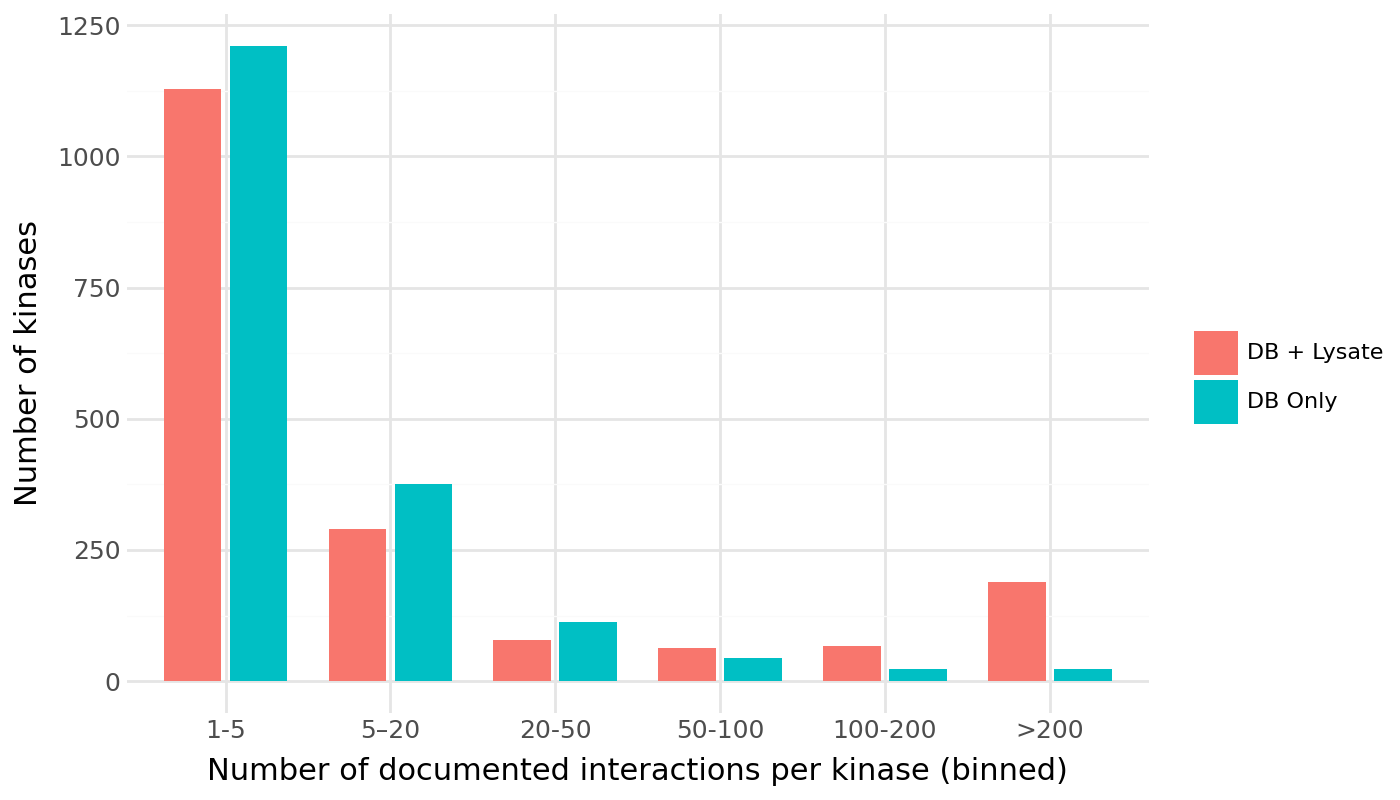

In [76]:
# Add source labels




plot_df = pd.concat([a, b], ignore_index=True)

# Ensure bin order is consistent (edit these labels to match yours)
bin_order = list(plot_df["interaction_bin"].dropna().unique())
# If you already have a known order list (recommended), use that instead:
# bin_order = ["1", "2–3", "4–10", "11–30", "31–100", ">100"]

plot_df["interaction_bin"] = pd.Categorical(
    plot_df["interaction_bin"],
    categories=bin_order,
    ordered=True
)

p = (
    ggplot(plot_df, aes(x="interaction_bin", y="n_kinases", fill="source"))
    + geom_col(position=position_dodge(width=0.8), width=0.7)
    + theme_minimal()
    + theme(
        axis_text_x=element_text(size=9),
        axis_text_y=element_text(size=9),
        legend_title=element_text(size=9),
        legend_text=element_text(size=8),
        figure_size=(7, 4)
    )
    + labs(
        x="Number of documented interactions per kinase (binned)",
        y="Number of kinases",
        fill=""
    )
)

p

In [84]:
wide_df = (
    plot_df
    .pivot_table(
        index="source",
        columns="interaction_bin",
        values="n_kinases",
        fill_value=0,
        aggfunc="sum"
    )
    .reset_index()
)
wide_df

/tmp/ipykernel_3889/3177027136.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior


interaction_bin,source,1-5,5–20,20-50,50-100,100-200,>200
0,DB + Lysate,1129,290,79,63,66,189
1,DB Only,1211,375,113,44,24,23


In [43]:
phosphoelm_accs_org = pd.merge(phosphoelm_accs,kinase_organism,on = 'kinase').drop_duplicates(['source','organism'])
phosphositeplus_accs_org = pd.merge(phosphositeplus_accs,kinase_organism,on = 'kinase').drop_duplicates(['source','organism'])
kinasephos_accs_org = pd.merge(kinasephos_accs,kinase_organism,on = 'kinase').drop_duplicates(['source','organism'])
lysate_accs_org = pd.merge(lysate_accs,kinase_organism,on = 'kinase').drop_duplicates(['source','organism'])

In [48]:
ks_dict = {"Phospho.ELM": list(set(phosphoelm_accs_org['organism'])),\
          "PhosphoSitePlus":list(set(phosphositeplus_accs_org['organism'])),\
          "Kinasephos3.0":list(set(kinasephos_accs_org['organism'])),\
          "Cell Lysate LC-MS":list(set(lysate_accs_org['organism']))
          }
upset_data_sub = upsetplot.from_contents(ks_dict)


# Create a taller figure
fig = plt.figure(figsize=(8, 10))  # increase height for longer figure

up = upsetplot.UpSet(
    upset_data_sub,
    show_counts=True,
    element_size=30,   # smaller dots/bars
)

up.plot(fig=fig)

# Reduce font sizes globally for this figure
for ax in fig.axes:
    ax.tick_params(labelsize=8)
    if ax.get_title():
        ax.title.set_fontsize(9)
    ax.xaxis.label.set_size(9)
    ax.yaxis.label.set_size(9)

# Save as PDF
# plt.show()
plt.savefig("eval_figs/ks_pair_upset_norganism.pdf", bbox_inches="tight")
plt.close()


/opt/conda/lib/python3.11/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/opt/conda/lib/python3.11/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/opt/conda/lib/

In [49]:
ks_dict = {"Phospho.ELM": list(set(phosphoelm_accs['kinase'])),\
          "PhosphoSitePlus":list(set(phosphositeplus_accs['kinase'])),\
          "Kinasephos3.0":list(set(kinasephos_accs['kinase'])),\
          "Cell Lysate LC-MS":list(set(lysate_accs['kinase']))
          }
upset_data_sub = upsetplot.from_contents(ks_dict)


# Create a taller figure
fig = plt.figure(figsize=(8, 10))  # increase height for longer figure

up = upsetplot.UpSet(
    upset_data_sub,
    show_counts=True,
    element_size=30,   # smaller dots/bars
)

up.plot(fig=fig)

# Reduce font sizes globally for this figure
for ax in fig.axes:
    ax.tick_params(labelsize=8)
    if ax.get_title():
        ax.title.set_fontsize(9)
    ax.xaxis.label.set_size(9)
    ax.yaxis.label.set_size(9)

# Save as PDF
plt.savefig("eval_figs/ks_pair_upset_nkinase.pdf", bbox_inches="tight")
plt.close()

/opt/conda/lib/python3.11/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/opt/conda/lib/python3.11/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/opt/conda/lib/